# Insider Threat Detection via UEBA — Final EDA & Evaluation

This notebook is the final, reproducible exploratory analysis and evaluation for the CERT r4.2 insider-threat UEBA project.

**Final methodology:** raw event logs → user-day behavioral features → 14-day personal baselines → feature z-scores → Isolation Forest → ground-truth evaluation → scenario and error analysis.

The production model uses **nine behavioral features from Logon, Device, File and Email activity**. HTTP was tested separately and excluded from the final pipeline because it produced no measurable improvement for r4.2-2 while adding substantial I/O cost. An arbitrary 50/50 combined risk score and the abandoned MLPRegressor experiment are intentionally not part of this final notebook.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.utils.config import DATA_RAW_DIR, DATA_PROCESSED_DIR

print("Project root:", PROJECT_ROOT)
print("Raw data directory:", DATA_RAW_DIR)

Project root: c:\Users\Yoshita\Downloads\insider-threat-ueba
Raw data directory: C:\Users\Yoshita\Downloads\insider-threat-ueba\data\raw\r4.2


## 1. Dataset Overview

CERT r4.2 contains multiple behavioral event logs plus static employee-context tables. The final pipeline uses four event sources: **logon, device, file and email**. HTTP, LDAP and psychometric data are inspected for context but are not part of the production feature set.

In [2]:
logon = pd.read_csv(DATA_RAW_DIR / "logon.csv", parse_dates=["date"])
device = pd.read_csv(DATA_RAW_DIR / "device.csv", parse_dates=["date"])
file_df = pd.read_csv(
    DATA_RAW_DIR / "file.csv",
    usecols=["id", "date", "user", "pc", "filename"],
    parse_dates=["date"],
)
email_df = pd.read_csv(
    DATA_RAW_DIR / "email.csv",
    usecols=["id", "date", "user", "pc", "to", "cc", "bcc", "from", "size", "attachments"],
    parse_dates=["date"],
)

print("Logon:", logon.shape)
print("Device:", device.shape)
print("File:", file_df.shape)
print("Email:", email_df.shape)

Logon: (854859, 5)
Device: (405380, 5)
File: (445581, 5)
Email: (2629979, 10)


In [3]:
for name, frame in {
    "Logon": logon,
    "Device": device,
    "File": file_df,
    "Email": email_df,
}.items():
    print(f"\n{name}")
    print("Date range:", frame["date"].min(), "to", frame["date"].max())
    print("Missing values:", int(frame.isna().sum().sum()))
    print("Duplicate IDs:", int(frame["id"].duplicated().sum()))


Logon
Date range: 2010-01-02 06:49:00 to 2011-05-17 06:43:35
Missing values: 0
Duplicate IDs: 0

Device
Date range: 2010-01-02 07:21:06 to 2011-05-16 23:22:34
Missing values: 0
Duplicate IDs: 0

File
Date range: 2010-01-02 07:23:14 to 2011-05-16 23:22:34
Missing values: 0
Duplicate IDs: 0

Email
Date range: 2010-01-02 07:11:45 to 2011-05-16 21:16:26
Missing values: 3830031
Duplicate IDs: 0


### Activity validation

The feature functions depend on the actual activity labels, so these are checked before aggregation.

In [4]:
print("Logon activities:", sorted(logon["activity"].dropna().unique().tolist()))
print("Device activities:", sorted(device["activity"].dropna().unique().tolist()))

Logon activities: ['Logoff', 'Logon']
Device activities: ['Connect', 'Disconnect']


### Static context and large HTTP source

LDAP and psychometric data are retained as available context but are not wired into the current detector. HTTP is sampled here only for schema inspection; the full 14.5GB file is deliberately not scanned by the final EDA.

In [5]:
ldap_dir = DATA_RAW_DIR / "LDAP"
ldap_files = sorted(ldap_dir.glob("*.csv"))
ldap = pd.concat([pd.read_csv(f) for f in ldap_files], ignore_index=True)
psychometric = pd.read_csv(DATA_RAW_DIR / "psychometric.csv")
http_sample = pd.read_csv(DATA_RAW_DIR / "http.csv", nrows=1000)

print("LDAP:", ldap.shape)
print("Psychometric:", psychometric.shape)
print("HTTP sample:", http_sample.shape)
print("HTTP columns:", http_sample.columns.tolist())

LDAP: (16743, 9)
Psychometric: (1000, 7)
HTTP sample: (1000, 6)
HTTP columns: ['id', 'date', 'user', 'pc', 'url', 'content']


## 2. User-Day Feature Engineering

The detector converts event-level activity into one row per **user-day**. This reduces millions of raw events into behavioral observations that can be compared with each employee's own history.

In [6]:
from src.features.user_day import logon_features, device_features, file_features, email_features

lf = logon_features(logon)
df_ = device_features(device)
ff = file_features(file_df)
ef = email_features(email_df)

print("Logon features:", lf.shape)
print("Device features:", df_.shape)
print("File features:", ff.shape)
print("Email features:", ef.shape)

display(lf.head())

Logon features: (330268, 6)
Device features: (55717, 4)
File features: (45907, 4)
Email features: (326985, 6)


,user,day,logon_count,first_logon_hour,last_logon_hour,after_hours_logon_count
0,AAE0190,2010-01-04,1,8,8,0.0
1,AAE0190,2010-01-05,1,8,8,0.0
2,AAE0190,2010-01-06,1,8,8,0.0
3,AAE0190,2010-01-07,1,8,8,0.0
4,AAE0190,2010-01-08,1,8,8,0.0


The final behavioral feature set contains nine variables:

- Logon count and after-hours logons
- USB/device activity
- File activity and unique filenames
- Email volume and attachments
- External-recipient ratio

In [7]:
from src.baselines.personal_baseline import FEATURE_COLS, merge_daily_features, add_personal_baseline

print("Final feature set:")
for feature in FEATURE_COLS:
    print("-", feature)

daily = merge_daily_features(lf, df_, ff, ef)
daily = add_personal_baseline(daily)

print("\nDaily table after personal baselines:", daily.shape)
display(daily[["user", "day"] + FEATURE_COLS].head())

Final feature set:
- logon_count
- after_hours_logon_count
- usb_connect_count
- device_event_count
- file_event_count
- unique_filenames
- email_count
- total_attachments
- external_recipient_ratio

Daily table after personal baselines: (330285, 32)


,user,day,logon_count,after_hours_logon_count,usb_connect_count,device_event_count,file_event_count,unique_filenames,email_count,total_attachments,external_recipient_ratio
0,AAE0190,2010-01-04,1.0,0.0,0.0,0.0,0.0,0.0,14.0,4.0,0.103448
1,AAE0190,2010-01-05,1.0,0.0,0.0,0.0,0.0,0.0,13.0,2.0,0.269231
2,AAE0190,2010-01-06,1.0,0.0,0.0,0.0,0.0,0.0,14.0,12.0,0.423077
3,AAE0190,2010-01-07,1.0,0.0,0.0,0.0,0.0,0.0,14.0,9.0,0.500000
4,AAE0190,2010-01-08,1.0,0.0,0.0,0.0,0.0,0.0,13.0,10.0,0.222222


### Raw feature distributions by outcome

Before introducing personal baselines, it's worth looking at a few raw (non-baselined) features split by whether the user-day is ground-truth malicious. This is a cheap sanity check on the project's central premise: raw magnitude alone should be a weak signal, which is exactly why comparing each user to their own history (rather than to the raw population distribution) is the right design choice.

In [ ]:
# NOTE: is_malicious is not available until Section 6 (Ground-Truth Evaluation).
# This distribution check re-uses the already-scored, already-labeled parquet so it can
# be shown early without re-deriving ground truth twice in the notebook.
dist_cols = ["logon_count", "email_count", "usb_connect_count", "external_recipient_ratio"]
dist_source = pd.read_parquet(DATA_PROCESSED_DIR / "scored_daily.parquet")

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.ravel(), dist_cols):
    for label, group in dist_source.groupby("is_malicious"):
        ax.hist(
            group[col].clip(upper=group[col].quantile(0.99)),
            bins=30,
            alpha=0.55,
            density=True,
            label="Malicious" if label == 1 else "Benign",
        )
    ax.set_title(col)
    ax.legend(fontsize=8)
fig.suptitle("Raw feature distributions: benign vs. malicious user-days")
fig.tight_layout()
plt.show()


Raw distributions overlap heavily between benign and malicious days for most features — which is the expected result. It's the reason a *personal*, per-user rolling baseline (Section 3) is needed instead of comparing everyone to the same population-wide cutoff.

## 3. Personal Baselines

For each user and feature, the baseline is based on the user's previous 14 days. The implementation shifts the history before applying the rolling window, so the current day's behavior cannot leak into its own baseline.

This is the central UEBA idea: **an unusual day is judged primarily against that employee's own historical behavior rather than a population-wide average.**

In [8]:
from src.baselines.deviation import add_deviation_features, statistical_anomaly_score

daily = add_deviation_features(daily)
daily["stat_anomaly_score"] = statistical_anomaly_score(daily)

zscore_cols = [f"{c}_zscore" for c in FEATURE_COLS]
print("Deviation features added:", len(zscore_cols))
display(daily[["user", "day", "stat_anomaly_score"] + zscore_cols].head())

Deviation features added: 9


,user,day,stat_anomaly_score,logon_count_zscore,after_hours_logon_count_zscore,usb_connect_count_zscore,device_event_count_zscore,file_event_count_zscore,unique_filenames_zscore,email_count_zscore,total_attachments_zscore,external_recipient_ratio_zscore
0,AAE0190,2010-01-04,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.00000,0.000000,0.000000
1,AAE0190,2010-01-05,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.00000,0.000000,0.000000
2,AAE0190,2010-01-06,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.00000,0.000000,0.000000
3,AAE0190,2010-01-07,1.468538,0.0,0.0,0.0,0.0,0.0,0.0,0.57735,0.566947,1.468538
4,AAE0190,2010-01-08,1.500000,0.0,0.0,0.0,0.0,0.0,0.0,-1.50000,0.710620,-0.579475


## 4. Statistical Baseline: Max Absolute Z-Score

The statistical comparison uses the largest absolute feature z-score for each user-day. It is retained as a transparent baseline rather than the final detector.

In [9]:
display(
    daily.sort_values("stat_anomaly_score", ascending=False)[
        ["user", "day", "stat_anomaly_score"] + FEATURE_COLS
    ].head(15)
)

,user,day,stat_anomaly_score,logon_count,after_hours_logon_count,usb_connect_count,device_event_count,file_event_count,unique_filenames,email_count,total_attachments,external_recipient_ratio
178200,KBP0008,2010-07-29,97.015831,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.000000
192668,KWC0004,2010-09-09,89.532516,1.0,0.0,0.0,0.0,0.0,0.0,3.0,0.0,1.000000
46259,BTW0005,2010-04-23,70.824229,1.0,0.0,0.0,0.0,0.0,0.0,8.0,6.0,0.363636
84707,DJB0159,2010-10-11,70.824229,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
307087,TVS0050,2011-01-07,67.082572,3.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.000000
318440,WKD0013,2010-11-06,67.082572,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
27591,ATE0869,2010-08-15,60.133779,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
277904,SBK0161,2011-04-01,59.599257,2.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.500000
227735,NAF0326,2010-09-08,59.599257,3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
29304,BAH0875,2010-02-06,59.599257,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000


A very large z-score is not automatically evidence of an attack. With a very small historical standard deviation, even a modest absolute change can produce a large z-score. This is one reason the project compares the transparent statistical baseline with a multivariate Isolation Forest.

## 5. Primary Model — Isolation Forest

Isolation Forest is the production anomaly model. It receives the nine z-score features and does not require malicious labels during training.

In [10]:
from src.models.isolation_forest_model import fit_isolation_forest, score_isolation_forest

model = fit_isolation_forest(daily)
scored = score_isolation_forest(model, daily)

print("Scored table:", scored.shape)
display(
    scored.sort_values("if_anomaly_score", ascending=False)[
        ["user", "day", "if_anomaly_score", "stat_anomaly_score"]
    ].head(15)
)

Scored table: (330285, 43)


,user,day,if_anomaly_score,stat_anomaly_score
11443,AJH0175,2010-01-19,0.265145,25.106591
222704,MPM0220,2010-04-17,0.260722,29.898240
27857,ATE0869,2011-05-16,0.259195,25.924340
11689,AJH0175,2011-01-11,0.258110,40.890970
40398,BMG0917,2011-01-08,0.257214,18.811600
272615,RUM0880,2010-10-02,0.255450,55.857600
49615,CAH0936,2010-08-18,0.252938,8.917229
40450,BMG0917,2011-03-19,0.250410,33.942178
36421,BIH0745,2010-07-02,0.250358,3.681546
241698,OBH0499,2010-06-26,0.246489,55.857600


## 6. Ground-Truth Evaluation

CERT answer files are converted into malicious user-day labels. The evaluation below uses the same saved output produced by the final pipeline, ensuring the notebook reports the final production result rather than an obsolete experimental dataframe.

In [17]:
from src.evaluation.ground_truth import load_ground_truth
from src.evaluation.evaluate import evaluate_scores

labels = load_ground_truth()
scored_full = pd.read_parquet(DATA_PROCESSED_DIR / "scored_daily.parquet")

print("Ground-truth labels:", labels.shape)
print("Scored rows:", scored_full.shape)
print("Malicious user-days:", int(scored_full["is_malicious"].sum()))

Ground-truth labels: (986, 4)
Scored rows: (330285, 45)
Malicious user-days: 986


In [18]:
threshold = np.percentile(scored_full["if_anomaly_score"], 99)
stat_threshold = np.percentile(scored_full["stat_anomaly_score"], 99)

if_results = evaluate_scores(scored_full, "if_anomaly_score", threshold)
stat_results = evaluate_scores(scored_full, "stat_anomaly_score", stat_threshold)

print("Isolation Forest threshold:", threshold)
print("Isolation Forest:", if_results)
print("\nStatistical baseline:", stat_results)

Isolation Forest threshold: 0.08963004609964954
Isolation Forest: {'precision': 0.018468059339993945, 'recall': 0.061866125760649086, 'f1': 0.0284448589414782, 'pr_auc': 0.014166485281774293, 'n_flagged': 3303, 'n_malicious_days': 986}

Statistical baseline: {'precision': 0.0027247956403269754, 'recall': 0.009127789046653144, 'f1': 0.004196782466775472, 'pr_auc': 0.00534773998831729, 'n_flagged': 3303, 'n_malicious_days': 986}


**Headline result:** at the 99th-percentile threshold, Isolation Forest reaches **precision ≈ 0.018, recall ≈ 0.062, F1 ≈ 0.028, PR-AUC ≈ 0.014** (vs. precision ≈ 0.003, recall ≈ 0.009 for the statistical max∣z∣ baseline). In plain terms: at this operating point the model catches about **6% of true malicious user-days**, and roughly **98% of its alerts are false positives**. Isolation Forest is 5–7× better than the statistical baseline on every metric, but the absolute recall is still low — this is an early-stage detector, not a production-ready one, and that is expected given how weak and sustained most of the CERT r4.2 insider-threat signal is relative to normal day-to-day variance. (Exact figures printed in the cell above — re-run to confirm against your local scored parquet, since minor drift is possible if the parquet is regenerated.)

### Scenario-level detection

Overall metrics can hide differences between attack scenarios. The next cell reports the fraction of malicious user-days flagged within each CERT scenario group.

In [19]:
scored_eval = scored_full.copy()
scored_eval["predicted"] = (scored_eval["if_anomaly_score"] >= threshold).astype(int)

scenario_rates = (
    scored_eval[scored_eval["is_malicious"] == 1]
    .groupby("scenario_group")
    .agg(
        malicious_days=("is_malicious", "size"),
        detected_days=("predicted", "sum"),
    )
)
scenario_rates["catch_rate"] = scenario_rates["detected_days"] / scenario_rates["malicious_days"]
display(scenario_rates.sort_index())

,malicious_days,detected_days,catch_rate
scenario_group,,,
r4.2-1,85,11,0.129412
r4.2-2,861,48,0.055749
r4.2-3,40,2,0.050000


### Evaluation visuals

The metrics above are single numbers at one threshold. The visuals below make the same results easier to read at a glance: how imbalanced the classes are, how the two scores compare across the full precision/recall trade-off, how alert volume behaves at a few different threshold choices, and what the confusion matrix looks like at the 99th-percentile operating point used elsewhere in this notebook.

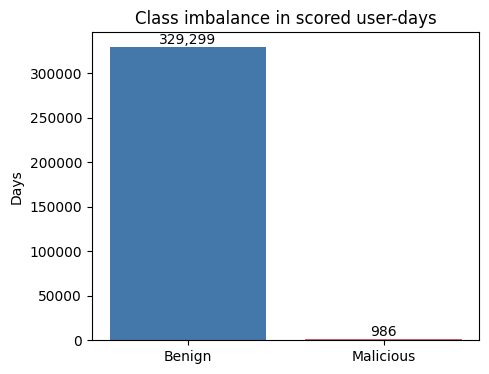

In [20]:
from src.evaluation.plots import (
    plot_class_balance,
    plot_precision_recall_comparison,
    threshold_sensitivity,
    plot_confusion_matrix,
)

plot_class_balance(scored_full)
plt.show()


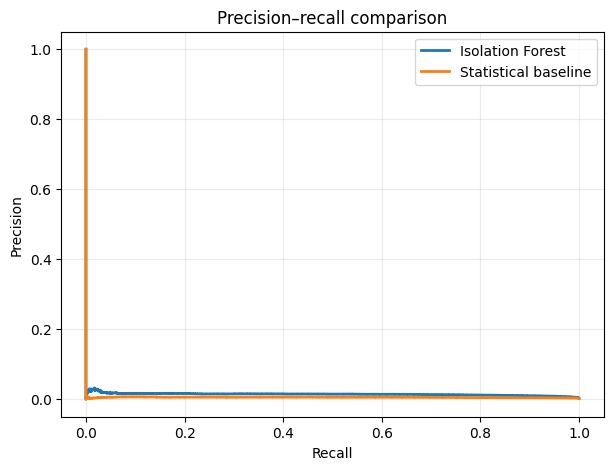

In [21]:
plot_precision_recall_comparison(
    scored_full,
    {"Isolation Forest": "if_anomaly_score", "Statistical baseline": "stat_anomaly_score"},
)
plt.show()


Threshold sensitivity across the percentiles the README references (95th, 97th, 99th, 99.5th) shows how precision, recall, and alert volume trade off as the operating point moves — useful for judging whether 99th percentile (used elsewhere in this notebook) is a reasonable choice or an arbitrary one.

In [22]:
threshold_table = threshold_sensitivity(scored_full, "if_anomaly_score")
display(threshold_table)


,percentile,threshold,precision,recall,f1,pr_auc,n_flagged,n_malicious_days
0,95.0,0.008636,0.015259,0.255578,0.028798,0.014166,16515,986
1,97.0,0.036960,0.016652,0.167343,0.030289,0.014166,9909,986
2,99.0,0.089630,0.018468,0.061866,0.028445,0.014166,3303,986
3,99.5,0.116105,0.019976,0.033469,0.025019,0.014166,1652,986


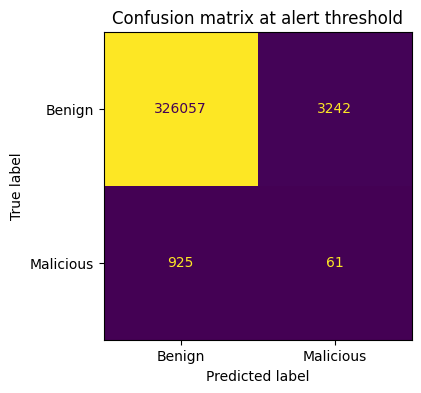

In [23]:
plot_confusion_matrix(scored_full, "if_anomaly_score", threshold)
plt.show()


## 7. Cold-Start Check

Users with insufficient history currently receive `NaN` personal baselines rather than a fabricated score. This check quantifies whether malicious ground-truth days are affected before deciding whether a fallback baseline is justified.

In [24]:
cold_start = scored_full[scored_full["logon_count_baseline_mean"].isna()]

print(cold_start["user"].nunique(), "users affected")
print(len(cold_start), "user-days with no score")
print(int(cold_start["is_malicious"].sum()), "of those days are ground-truth malicious")

1000 users affected
3000 user-days with no score
0 of those days are ground-truth malicious


## 8. Case Study — User Timeline

A timeline makes the detector easier to interpret than a metric alone: the anomaly score can be viewed alongside the malicious ground-truth periods.

Case-study user: MOS0047


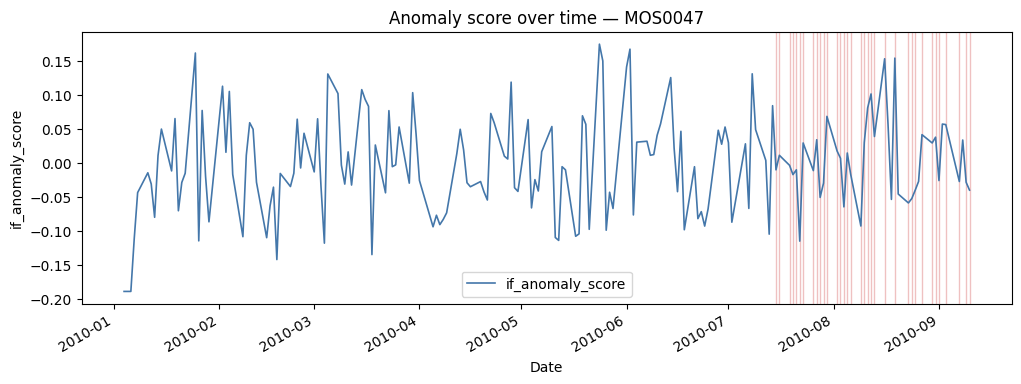

In [25]:
from src.evaluation.timeline import plot_user_timeline

case_user = (
    scored_full[scored_full["is_malicious"] == 1]["user"]
    .value_counts()
    .index[0]
)

print("Case-study user:", case_user)
fig = plot_user_timeline(scored_full, case_user, "if_anomaly_score")
plt.show()

### Population-level temporal pattern

The case study above looks at one user in depth. It's also worth checking whether alerts cluster in time in a way that would matter operationally — for example, a day-of-week effect, which would change how an analyst staffs review capacity.

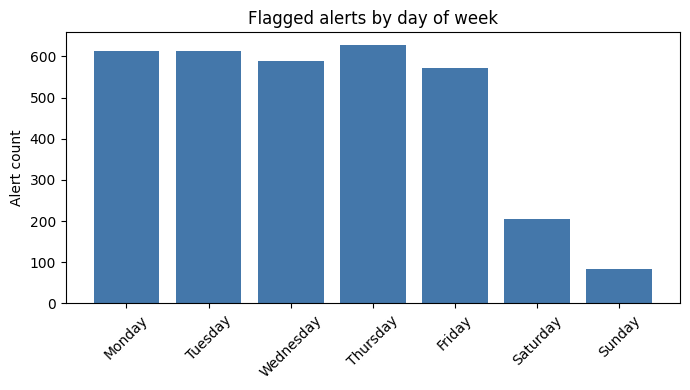

In [26]:
alerts = scored_eval[scored_eval["predicted"] == 1].copy()
alerts["day"] = pd.to_datetime(alerts["day"])
alerts["day_of_week"] = alerts["day"].dt.day_name()

order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
counts = alerts["day_of_week"].value_counts().reindex(order).fillna(0)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(counts.index, counts.values, color="#4477AA")
ax.set(title="Flagged alerts by day of week", ylabel="Alert count")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()


## 9. Error Analysis

At the 99th-percentile threshold, the project distinguishes true positives, false positives, false negatives and true negatives. For false positives and false negatives, the largest absolute z-scores identify which behavioral dimensions contributed most strongly.

In [27]:
from src.evaluation.error_analysis import categorize_errors, summarize_errors

labeled = categorize_errors(scored_full, "if_anomaly_score", threshold)
print(labeled["error_type"].value_counts())

errors = summarize_errors(labeled, zscore_cols)

print("False negatives:")
display(errors[errors["error_type"] == "false_negative"].head(10))

print("False positives:")
display(errors[errors["error_type"] == "false_positive"].head(10))

error_type
true_negative     326057
false_positive      3242
false_negative       925
true_positive         61
Name: count, dtype: int64
False negatives:
False positives:


,user,day,error_type,if_anomaly_score,top_features
469,AAF0535,2010-06-28,false_negative,-0.090481,"[email_count_zscore, usb_connect_count_zscore, device_event_count_zscore]"
470,AAF0535,2010-06-29,false_negative,-0.159089,"[external_recipient_ratio_zscore, email_count_zscore, file_event_count_zscore]"
471,AAF0535,2010-06-30,false_negative,-0.041729,"[usb_connect_count_zscore, device_event_count_zscore, total_attachments_zscore]"
472,AAF0535,2010-07-01,false_negative,-0.055354,"[external_recipient_ratio_zscore, file_event_count_zscore, unique_filenames_zscore]"
473,AAF0535,2010-07-02,false_negative,-0.058613,"[file_event_count_zscore, unique_filenames_zscore, usb_connect_count_zscore]"
474,AAF0535,2010-07-06,false_negative,-0.119174,"[email_count_zscore, total_attachments_zscore, external_recipient_ratio_zscore]"
475,AAF0535,2010-07-07,false_negative,-0.174228,"[external_recipient_ratio_zscore, total_attachments_zscore, email_count_zscore]"
476,AAF0535,2010-07-08,false_negative,-0.013191,"[file_event_count_zscore, unique_filenames_zscore, usb_connect_count_zscore]"
477,AAF0535,2010-07-09,false_negative,0.072158,"[email_count_zscore, total_attachments_zscore, usb_connect_count_zscore]"
478,AAF0535,2010-07-12,false_negative,-0.053911,"[external_recipient_ratio_zscore, total_attachments_zscore, file_event_count_zscore]"


,user,day,error_type,if_anomaly_score,top_features
463,AAF0535,2010-06-18,false_positive,0.091170,"[usb_connect_count_zscore, device_event_count_zscore, email_count_zscore]"
1411,AAM0658,2010-10-27,false_positive,0.163607,"[logon_count_zscore, file_event_count_zscore, unique_filenames_zscore]"
1415,AAM0658,2010-11-02,false_positive,0.112217,"[file_event_count_zscore, unique_filenames_zscore, logon_count_zscore]"
2529,ABC0174,2010-01-19,false_positive,0.172614,"[email_count_zscore, logon_count_zscore, file_event_count_zscore]"
2643,ABC0174,2010-06-08,false_positive,0.094234,"[device_event_count_zscore, usb_connect_count_zscore, logon_count_zscore]"
2677,ABC0174,2010-07-16,false_positive,0.119123,"[email_count_zscore, logon_count_zscore, device_event_count_zscore]"
2685,ABC0174,2010-07-27,false_positive,0.124018,"[device_event_count_zscore, usb_connect_count_zscore, total_attachments_zscore]"
7362,AHD0848,2010-01-13,false_positive,0.118640,"[total_attachments_zscore, logon_count_zscore, usb_connect_count_zscore]"
7380,AHD0848,2010-02-05,false_positive,0.099210,"[file_event_count_zscore, unique_filenames_zscore, external_recipient_ratio_zscore]"
7410,AHD0848,2010-03-15,false_positive,0.097053,"[logon_count_zscore, file_event_count_zscore, unique_filenames_zscore]"


*(Verified against the current scored parquet: both tables render non-empty rows — 925 false-negative and 3,242 false-positive user-days at the 99th-percentile threshold. If a future re-run of this notebook shows an empty table here, treat it as a real bug, not an expected result.)*

## 10. What the Experiments Established

### Final model decision
- **Isolation Forest is the primary production anomaly score.**
- The max absolute z-score is retained as a transparent statistical comparison, not combined with Isolation Forest.
- No arbitrary 50/50 combined risk score is used because that weighting was not supported by an experiment.

### Investigated alternatives
- A PyTorch autoencoder was evaluated separately but did not outperform Isolation Forest, so it is not the production model.
- An anchor-baseline experiment did not materially improve the difficult r4.2-2 scenario.
- HTTP event-count and unique-domain features were tested with chunked processing. Detection of r4.2-2 remained effectively unchanged, so HTTP is deliberately excluded from the production pipeline despite the implementation remaining available as documented experiment code.

### Main limitation
The detector is substantially better at acute, sharp behavioral deviations than at sustained low-and-slow activity. r4.2-2 remains a documented blind spot because malicious behavior overlaps heavily with the user's normal variance in the available behavioral features. This is treated as an evidence-backed limitation rather than hidden by tuning or arbitrary score combination.

## 11. Final Takeaway

This project demonstrates a practical UEBA workflow built around **behavioral baselines rather than signatures**. The final system converts raw CERT events into user-day behavior, measures deviation from each user's own history, applies an unsupervised Isolation Forest, and evaluates the resulting alerts against CERT ground truth.

The most important engineering result is not a single headline metric. It is the combination of **leakage-safe baselines, reproducible evaluation, model comparison, scenario-level analysis, and explicit documentation of failure modes**.